# Mantis – Spain demo data (SIGPAC, Aragón)

**Goal:** build the two input files of the Mantis app (parcels GeoJSON + NDVI table)
from open data only — no hackathon or personal data.

## Pipeline
1. **Tools** – geopandas, duckdb, pystac-client, planetary-computer, stackstac
2. **Source** – SIGPAC Aragón as GeoParquet (fiboa / Source Cooperative), CC-BY-4.0, 4,146,895 parcels
   - FEGA ATOM feed tried first → hangs from Colab, dropped
   - DuckDB reads the file over HTTP, only the needed columns (no full download)
3. **Crops** – OLIVAR (227,274 parcels in Aragón) + VIÑEDO; mixed parcels (e.g. VIÑEDO - OLIVAR) excluded
4. **Place** – ranked municipalities by min(vines, olives):
   - Alcañiz (44/13) rejected: 10,807 olives but only 38 vines
   - **Borja area (50/55)** chosen: 2,158 vines + 2,523 olives
5. **Parcels** – geometry in EPSG:25830, area in m²; small parcels to be filtered (10 m pixels)
6. **Next** – Sentinel-2 L2A NDVI (Planetary Computer), 36 ten-day values per parcel → `d01…d36`
7. **Output** – `parcels_es.geojson` + `ndvi_es.csv`, same columns as the Dutch demo

*Data: SIGPAC (FEGA / Gobierno de Aragón) via fiboa, CC-BY-4.0. Imagery: Copernicus Sentinel-2.*

In [1]:
# Cell 1: install tools
!pip -q install geopandas pyogrio pystac-client planetary-computer stackstac duckdb

In [2]:
# Cell 2: query the Aragón SIGPAC file in the cloud (no full download)
!pip -q install duckdb
import duckdb

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")

URL = "https://data.source.coop/fiboa/es-ar/es_ar.parquet"

# 1) how many parcels in total
print("Total parcels:", con.execute(f"SELECT COUNT(*) FROM read_parquet('{URL}')").fetchone()[0])

# 2) which crop names mention olives, and how many parcels each
df = con.execute(f'''
    SELECT "crop:name", "crop:name_en", COUNT(*) AS n
    FROM read_parquet('{URL}')
    WHERE upper("crop:name") LIKE '%OLIV%'
    GROUP BY 1, 2
    ORDER BY n DESC
''').df()
print(df)

Total parcels: 4146895


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                    crop:name                    crop:name_en       n
0                      OLIVAR                     OLIVE GROVE  227274
1             OLIVAR - FRUTAL                  OLIVAR – FRUIT     507
2             VIÑEDO - OLIVAR          VINEYARD – OLIVE GROVE     396
3       FRUTOS SECOS Y OLIVAR   DRIED FRUITS AND OLIVE GROVES     371
4  ASOCIACIÓN OLIVAR-CÍTRICOS  OLIVE GROVE-CITRUS ASSOCIATION       8


In [3]:
# Cell 3: top municipalities by number of OLIVAR parcels
top = con.execute(f'''
    SELECT admin_province_code AS prov,
           admin_municipality_code AS muni,
           COUNT(*) AS n_olive
    FROM read_parquet('{URL}')
    WHERE "crop:name" = 'OLIVAR'
    GROUP BY 1, 2
    ORDER BY n_olive DESC
    LIMIT 15
''').df()
print(top)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   prov muni  n_olive
0    44   13    10807
1    44    8     7859
2    50  153     7355
3    44   14     6010
4    44  254     5745
5    44   49     5516
6    50   45     5404
7    50   74     5268
8    44   25     5085
9    44  154     4679
10   44   51     4596
11   44   22     4271
12   44  261     3953
13   50  166     3872
14   44  260     3760


In [4]:
# Cell 4: download OLIVAR + VIÑEDO parcels for Zaragoza 50 / municipality 55
import geopandas as gpd
from shapely import wkb

q = f'''
    SELECT id, "crop:name" AS crop, "crop:name_en" AS crop_en,
           admin_province_code AS prov, admin_municipality_code AS muni,
           geometry
    FROM read_parquet('{URL}')
    WHERE ( "crop:name" = 'OLIVAR'
            OR ("crop:name" LIKE 'VIÑEDO%' AND "crop:name" NOT LIKE '%OLIVAR%') )
      AND CAST(admin_province_code AS INTEGER) = 50
      AND CAST(admin_municipality_code AS INTEGER) = 55
'''
raw = con.execute(q).df()

gdf = gpd.GeoDataFrame(raw.drop(columns="geometry"),
                       geometry=raw["geometry"].apply(lambda b: wkb.loads(bytes(b))),
                       crs="EPSG:25830")
gdf["area_m2"] = gdf.geometry.area.round(0)

print(len(gdf), "parcels")
print(gdf["crop"].value_counts())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

4681 parcels
crop
OLIVAR             2523
VIÑEDO             2152
VIÑEDO - FRUTAL       6
Name: count, dtype: int64


In [5]:
# Cell 4b: municipalities ranked by vineyard parcels, with olive counts alongside
both = con.execute(f'''
    SELECT CAST(admin_province_code AS INTEGER) AS prov,
           CAST(admin_municipality_code AS INTEGER) AS muni,
           SUM(CASE WHEN "crop:name" LIKE 'VIÑEDO%'
                     AND "crop:name" NOT LIKE '%OLIVAR%' THEN 1 ELSE 0 END) AS n_vine,
           SUM(CASE WHEN "crop:name" = 'OLIVAR' THEN 1 ELSE 0 END)         AS n_olive
    FROM read_parquet('{URL}')
    GROUP BY 1, 2
    HAVING n_vine > 0 AND n_olive > 0
    ORDER BY LEAST(n_vine, n_olive) DESC
    LIMIT 15
''').df()
print(both)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

    prov  muni  n_vine  n_olive
0     50    55  2158.0   2523.0
1     50   154  1342.0   1715.0
2     22    61  1266.0   1900.0
3     50   114  3506.0    796.0
4     50     6   828.0    633.0
5     50   252   697.0    621.0
6     22   277   560.0    732.0
7     50    88   576.0    469.0
8     22   161   446.0    985.0
9     50    24   969.0    434.0
10    50    27   405.0   2007.0
11    50    61   400.0    669.0
12    50   190   377.0   1953.0
13    50   153   334.0   7355.0
14    50    10   313.0    331.0


In [6]:
# Cell 5: keep parcels big enough for Sentinel-2, check location, save GeoJSON
MIN_AREA = 2000   # m²  → at least ~20 pixels of 10 m

big = gdf[(gdf["area_m2"] >= MIN_AREA) & (gdf["crop"].isin(["OLIVAR", "VIÑEDO"]))].copy()
print("All parcels:", len(gdf), "| kept (>= %d m²):" % MIN_AREA, len(big))
print(big["crop"].value_counts())
print(big.groupby("crop")["area_m2"].median().round(0).rename("median_m2"))

# where is it? (centre of all kept parcels, in lat/lon)
c = big.to_crs(4326).geometry.unary_union.centroid
print(f"Centre: lat {c.y:.4f}, lon {c.x:.4f}")

# save for the app (Leaflet wants lat/lon = EPSG:4326)
out = big.to_crs(4326)[["id", "crop", "crop_en", "area_m2", "geometry"]]
out["id"] = out["id"].astype(float).astype("int64").astype(str)
out.to_file("parcels_es.geojson", driver="GeoJSON")
print("Saved parcels_es.geojson")

All parcels: 4681 | kept (>= 2000 m²): 2122
crop
VIÑEDO    1371
OLIVAR     751
Name: count, dtype: int64
crop
OLIVAR    3165.0
VIÑEDO    5122.0
Name: median_m2, dtype: float64


/tmp/ipykernel_2070/3491667378.py:10: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  c = big.to_crs(4326).geometry.unary_union.centroid


Centre: lat 41.8411, lon -1.5383
Saved parcels_es.geojson


In [7]:
# Cell 6: pick a demo farm = 5 olive + 5 vine parcels close together
import numpy as np
import pandas as pd

cand = big[big["area_m2"] >= 3000].copy()          # a bit bigger = cleaner NDVI
cand["px"] = cand.geometry.centroid.x
cand["py"] = cand.geometry.centroid.y
olv = cand[cand["crop"] == "OLIVAR"]
vin = cand[cand["crop"] == "VIÑEDO"]

# for each olive parcel: how many vines within 1 km?
V = vin[["px", "py"]].to_numpy()
olv = olv.assign(vines_1km=[(np.hypot(V[:,0]-x, V[:,1]-y) < 1000).sum()
                            for x, y in zip(olv["px"], olv["py"])])
seed = olv.sort_values("vines_1km", ascending=False).iloc[0]
print("Seed olive parcel:", seed["id"], "| vines within 1 km:", seed["vines_1km"])

# 5 nearest olives + 5 nearest vines to the seed
def nearest(df, n=5):
    d = np.hypot(df["px"] - seed["px"], df["py"] - seed["py"])
    return df.assign(dist_m=d.round(0)).nsmallest(n, "dist_m")

farm = gpd.GeoDataFrame(pd.concat([nearest(olv), nearest(vin)]), crs=big.crs)
farm["id"] = farm["id"].astype(str).str.replace(".0", "", regex=False)
print(farm[["id", "crop", "area_m2", "dist_m"]])

farm.to_crs(4326)[["id", "crop", "crop_en", "area_m2", "geometry"]] \
    .to_file("demo_farm_es.geojson", driver="GeoJSON")
print("Saved demo_farm_es.geojson")

farm.to_crs(4326).explore(column="crop", tiles="Esri.WorldImagery")

Seed olive parcel: 981302571.0 | vines within 1 km: 131
             id    crop  area_m2  dist_m
775   981302571  OLIVAR   4434.0     0.0
753   981302100  OLIVAR   3323.0   234.0
782   981305849  OLIVAR   9033.0   246.0
785   981299842  OLIVAR   4749.0   251.0
786   981299938  OLIVAR   5837.0   274.0
770  1305084562  VIÑEDO   4186.0    64.0
766   918770767  VIÑEDO  18200.0    83.0
777   981302601  VIÑEDO   3367.0    95.0
774   918770779  VIÑEDO   3048.0    96.0
776   981302602  VIÑEDO   7938.0   108.0
Saved demo_farm_es.geojson


37 scenes


/tmp/ipykernel_2070/2771842320.py:36: RuntimeWarning: Mean of empty slice
  series[p["id"]] = pd.Series(np.where(ok, np.nanmean(ts, axis=1), np.nan),
/tmp/ipykernel_2070/2771842320.py:36: RuntimeWarning: Mean of empty slice
  series[p["id"]] = pd.Series(np.where(ok, np.nanmean(ts, axis=1), np.nan),
/tmp/ipykernel_2070/2771842320.py:36: RuntimeWarning: Mean of empty slice
  series[p["id"]] = pd.Series(np.where(ok, np.nanmean(ts, axis=1), np.nan),
/tmp/ipykernel_2070/2771842320.py:36: RuntimeWarning: Mean of empty slice
  series[p["id"]] = pd.Series(np.where(ok, np.nanmean(ts, axis=1), np.nan),
/tmp/ipykernel_2070/2771842320.py:36: RuntimeWarning: Mean of empty slice
  series[p["id"]] = pd.Series(np.where(ok, np.nanmean(ts, axis=1), np.nan),
/tmp/ipykernel_2070/2771842320.py:36: RuntimeWarning: Mean of empty slice
  series[p["id"]] = pd.Series(np.where(ok, np.nanmean(ts, axis=1), np.nan),
/tmp/ipykernel_2070/2771842320.py:36: RuntimeWarning: Mean of empty slice
  series[p["id"]] = pd.Ser

              crop  peak_ndvi peak_decade  season_integral
parcel_id                                                 
981302571   OLIVAR      0.626         d01            17.49
981302100   OLIVAR      0.829         d29            15.22
981305849   OLIVAR      0.597         d03            16.24
981299842   OLIVAR      0.458         d03            11.39
981299938   OLIVAR      0.425         d33            10.33
1305084562  VIÑEDO      0.603         d29            12.28
918770767   VIÑEDO      0.434         d28             9.25
981302601   VIÑEDO      0.660         d34            11.23
918770779   VIÑEDO        NaN         NaN             0.00
981302602   VIÑEDO      0.588         d34            10.36


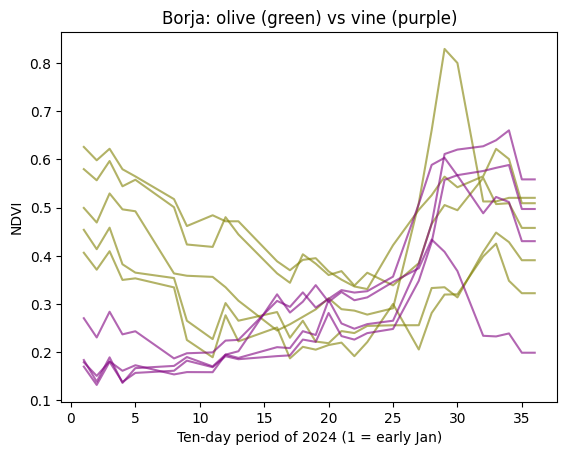

In [8]:
# Cell 7: Sentinel-2 L2A NDVI for the demo farm, 2024 -> 36 ten-day values per parcel
import pystac_client, planetary_computer, stackstac
from rasterio.features import geometry_mask
import matplotlib.pyplot as plt

farm_utm = farm.to_crs(32630)                       # Sentinel-2 grid here = UTM 30N
minx, miny, maxx, maxy = farm_utm.total_bounds
bounds = (minx-50, miny-50, maxx+50, maxy+50)       # small box around the farm

cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                modifier=planetary_computer.sign_inplace)
items = cat.search(collections=["sentinel-2-l2a"],
                   bbox=farm.to_crs(4326).total_bounds.tolist(),
                   datetime="2024-01-01/2024-12-31",
                   query={"eo:cloud_cover": {"lt": 40}}).item_collection()
print(len(items), "scenes")

stack = stackstac.stack(items, assets=["B04", "B08", "SCL"],
                        epsg=32630, resolution=10, bounds=bounds).compute()

# reflectance: since 2022 Sentinel-2 L2A has a +1000 offset in the raw numbers
red = (stack.sel(band="B04") - 1000) / 10000
nir = (stack.sel(band="B08") - 1000) / 10000
scl = stack.sel(band="SCL")
ndvi = ((nir - red) / (nir + red)).where(scl.isin([4, 5]))   # keep only vegetation / bare soil

# mean NDVI per parcel per date (10 m inward buffer, like OPEKEPE)
H, W = stack.sizes["y"], stack.sizes["x"]
series = {}
for _, p in farm_utm.iterrows():
    g = p.geometry.buffer(-10)
    g = p.geometry if g.is_empty else g
    m = ~geometry_mask([g], out_shape=(H, W), transform=stack.attrs["transform"])
    ts = ndvi.values[:, m]
    ok = np.isfinite(ts).sum(axis=1) >= max(3, 0.5 * m.sum())
    series[p["id"]] = pd.Series(np.where(ok, np.nanmean(ts, axis=1), np.nan),
                                index=pd.to_datetime(ndvi.time.values))
df = pd.DataFrame(series)

# 36 ten-day periods (dekads): 1-10, 11-20, 21-end of each month
dek = (df.index.month - 1) * 3 + np.minimum((df.index.day - 1) // 10, 2) + 1
d = df.groupby(dek).mean().reindex(range(1, 37)).interpolate(limit_direction="both")

out = d.T
cols = [f"d{i:02d}" for i in range(1, 37)]
out.columns = cols
out.insert(0, "crop", farm.set_index("id").loc[out.index, "crop"].values)
out["peak_ndvi"] = out[cols].max(axis=1).round(3)
out["peak_decade"] = out[cols].idxmax(axis=1)
out["season_integral"] = out[cols].sum(axis=1).round(2)
out.index.name = "parcel_id"
out.to_csv("ndvi_es.csv")
print(out[["crop", "peak_ndvi", "peak_decade", "season_integral"]])

# the picture for the slide: olive vs vine
for crop, color in [("OLIVAR", "olive"), ("VIÑEDO", "purple")]:
    for _, r in out[out["crop"] == crop].iterrows():
        plt.plot(range(1, 37), r[cols].values, color=color, alpha=0.6)
plt.xlabel("Ten-day period of 2024 (1 = early Jan)"); plt.ylabel("NDVI")
plt.title("Borja: olive (green) vs vine (purple)"); plt.show()

6. NDVI – Sentinel-2 L2A 2024 (Planetary Computer), cloud <40%, SCL mask 4/5, −1000 offset, 10 m inward buffer, 36 dekads → `ndvi_es.csv`

In [9]:
# Cell 7b: sanity check - monthly median NDVI per crop + clear dates per month
crop_of = farm.set_index("id")["crop"]
long = df.stack().rename("ndvi").reset_index()
long.columns = ["date", "parcel_id", "ndvi"]
long["month"] = long["date"].dt.month
long["crop"] = long["parcel_id"].map(crop_of)

print(long.pivot_table(index="month", columns="crop", values="ndvi",
                       aggfunc="median").round(2))
print("\nClear dates per month:",
      df.notna().any(axis=1).groupby(df.index.month).sum().to_dict())

crop   OLIVAR  VIÑEDO
month                
1        0.50    0.18
2        0.49    0.16
3        0.36    0.18
4        0.35    0.19
5        0.31    0.20
6        0.27    0.26
7        0.30    0.30
8        0.29    0.29
9        0.30    0.35
10       0.49    0.56
11       0.51    0.55
12       0.46    0.50

Clear dates per month: {1: 3, 2: 3, 3: 2, 4: 3, 5: 1, 6: 3, 7: 6, 8: 4, 9: 3, 10: 3, 11: 2, 12: 2}


In [10]:
# Cell 9: export the Borja farm for the Mantis web app (same structure as the app's DATA)
import json
from shapely.geometry import mapping


code = {"OLIVAR": "OV", "VIÑEDO": "VI"}                 # SIGPAC use codes
ok_ids = out.index[out[cols].notna().all(axis=1)]      # skip parcels with no NDVI
g = farm.to_crs(4326).set_index("id").loc[ok_ids]

def geom6(geom):
    """GeoJSON geometry with coordinates rounded to 6 decimals (~10 cm)."""
    return json.loads(json.dumps(mapping(geom)), parse_float=lambda x: round(float(x), 6))

parcels = []
for pid, row in g.iterrows():
    parcels.append({
        "id":   pid,
        "crop": code[row["crop"]],
        "real": row["crop"],                            # what SIGPAC says
        "ha":   round(row["area_m2"] / 10000, 2),
        "geom": geom6(row.geometry),
        "ndvi": [round(float(v), 3) for v in out.loc[pid, cols]],
    })

with open("mantis_data_borja.json", "w", encoding="utf-8") as f:
    json.dump({"parcels": parcels}, f, ensure_ascii=False, separators=(",", ":"))

print(len(parcels), "parcels exported")
print({k: v for k, v in parcels[0].items() if k != "geom"})


9 parcels exported
{'id': '981302571', 'crop': 'OV', 'real': 'OLIVAR', 'ha': 0.44, 'ndvi': [0.626, 0.598, 0.622, 0.58, 0.565, 0.549, 0.533, 0.518, 0.462, 0.473, 0.484, 0.472, 0.472, 0.444, 0.416, 0.389, 0.37, 0.392, 0.395, 0.368, 0.351, 0.337, 0.331, 0.377, 0.422, 0.459, 0.496, 0.526, 0.564, 0.542, 0.554, 0.565, 0.622, 0.601, 0.509, 0.509]}


In [11]:
# Cell 10 (v2, 31 Oct: CSV export, 'review needed' label, new footer) — build the Mantis app from this notebook's data and show it here.
# The app template is stored inside this cell (compressed), so no upload is needed.
import json, html, gzip, base64
from IPython.display import HTML, display

# 1. the app template (HTML + JS of Mantis, data replaced by __MANTIS_DATA__), gzip + base64
TEMPLATE_B64 = """
...
"""
tpl = gzip.decompress(base64.b64decode("".join(TEMPLATE_B64.split()))).decode("utf-8")
assert "__MANTIS_DATA__" in tpl

# 2. the parcels exported by Cell 9
with open("mantis_data_borja.json", encoding="utf-8") as f:
    data = json.load(f)
print("parcels:", len(data["parcels"]))

# 3. fill the template and save a standalone web page
page = tpl.replace("__MANTIS_DATA__", json.dumps(data, ensure_ascii=False, separators=(",", ":")))
with open("index.html", "w", encoding="utf-8") as f:
    f.write(page)
print("index.html written:", round(len(page)/1024), "KB")

# 4. show the app inside the notebook
display(HTML(f'<iframe srcdoc="{html.escape(page)}" width="100%" height="820" style="border:0"></iframe>'))


parcels: 9
index.html written: 221 KB


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [12]:
# Cell 11 — open the app in a normal browser tab (served from this Colab session)
import subprocess, time
from google.colab import output

# start a small web server in the folder where index.html is
server = subprocess.Popen(["python", "-m", "http.server", "8000"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(1)

# open it in a new browser tab
output.serve_kernel_port_as_window(8000, path="/index.html")

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>